# 04 — Baseline KNN (`Training / Development Data` Only)

**Modul Inti:** [`src/baseline_knn.py`](../src/baseline_knn.py)  
**Skrip CLI:** [`src/04_baseline_knn.py`](../src/04_baseline_knn.py)  
**Laporan:** [`Laporan_Baseline_KNN_DIFW_KNN.md`](../Laporan_Baseline_KNN_DIFW_KNN.md)

Sesuai *flowchart* penelitian, tahap ini membangun cabang kiri **Baseline KNN** secara eksklusif di atas **`Training / Development Data` (`36.168` baris)**; **`Hold-out Test Data` (`9.043` baris) tetap dikunci** hingga Tahap 07 (*Final Model Evaluation*):
1. Verifikasi kesetaraan matematis implementasi cepat `NearestNeighbors` vs `KNeighborsClassifier` pada `Fold 0`.
2. Evaluasi profil dasar **`E0 (Standard KNN: k=5, uniform)`** dan referensi `k=5, distance` pada 5 lipatan pengembangan (*Out-of-Fold Development*).
3. Diagnosis empiris kelemahan jarak Euclidean seragam pada kelas minoritas `yes` (`11,70%`) sebelum menuju Tahap 06 (*Cross-Validation & Hyperparameter Tuning*).

## 1. Muat `Training / Development Data` & Verifikasi Ekuivalensi `NearestNeighbors`

In [1]:
import importlib.util
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 120, 'axes.edgecolor': '#CCCCCC', 'axes.grid': True,
    'grid.alpha': 0.3, 'grid.linestyle': '--', 'axes.titleweight': 'bold',
})

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import BaselineEuclideanPreprocessor
from src.baseline_knn import verify_knn_probability_equivalence

spec = importlib.util.spec_from_file_location('b04', PROJECT_ROOT / 'src' / '04_baseline_knn.py')
b04 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(b04)

train_df = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'train_split.csv')
folds_df = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'train_cv_folds.csv')
X_train_df = train_df.drop(columns=['y'])
y_train = train_df['y'].to_numpy(dtype=np.int64)
fold_ids = folds_df['fold_id'].to_numpy(dtype=np.int64)

print(f'Training/Development shape: {X_train_df.shape} | positive rate: {100*y_train.mean():.4f}%')
print('Hold-out Test Data tidak dimuat (dikunci hingga Tahap 07).')

val0 = fold_ids == 0
prep0 = BaselineEuclideanPreprocessor()
X_tr0 = prep0.fit_transform(X_train_df.loc[~val0].reset_index(drop=True))
X_va0 = prep0.transform(X_train_df.loc[val0].reset_index(drop=True))
eq_df = verify_knn_probability_equivalence(X_tr0, y_train[~val0], X_va0)
display(eq_df)

Training/Development shape: (36168, 15) | positive rate: 11.6982%
Hold-out Test Data tidak dimuat (dikunci hingga Tahap 07).


,k,weights,max_prob_abs_diff_k,max_dist_trunc_diff,n_boundary_tie_rows_maxk,status
0,5,uniform,0.000000e+00,0.0,2,PASS
1,5,distance,2.220446e-16,0.0,2,PASS
2,21,uniform,0.000000e+00,0.0,0,PASS
3,21,distance,3.330669e-16,0.0,0,PASS


## 2. Profil Kinerja Baseline KNN (`E0`) pada 5-Fold Development Set

In [2]:
per_fold_df, summary_df, oof_probs = b04.evaluate_baseline_on_dev_folds(
    X_train_df=X_train_df, y_train=y_train, fold_ids=fold_ids
)
disp_cols = ['variant', 'k', 'weights', 'accuracy_mean', 'precision_yes_mean', 'recall_yes_mean', 'f1_yes_mean', 'pr_auc_mean', 'roc_auc_mean', 'mcc_mean', 'g_mean_mean']
display(summary_df[disp_cols])
display(summary_df[['variant', 'oof_tn', 'oof_fp', 'oof_fn', 'oof_tp']])

,variant,k,weights,accuracy_mean,precision_yes_mean,recall_yes_mean,f1_yes_mean,pr_auc_mean,roc_auc_mean,mcc_mean,g_mean_mean
0,E0_Standard_k5_uniform,5,uniform,0.8863,0.5364,0.2026,0.2938,0.2823,0.6896,0.2804,0.4444
1,Ref_Euclidean_k5_distance,5,distance,0.8838,0.5078,0.2113,0.2982,0.3105,0.6925,0.2750,0.4531


,variant,oof_tn,oof_fp,oof_fn,oof_tp
0,E0_Standard_k5_uniform,31197,740,3374,857
1,Ref_Euclidean_k5_distance,31072,865,3337,894


## 3. Visualisasi Diagnostik Baseline pada Data Pengembangan

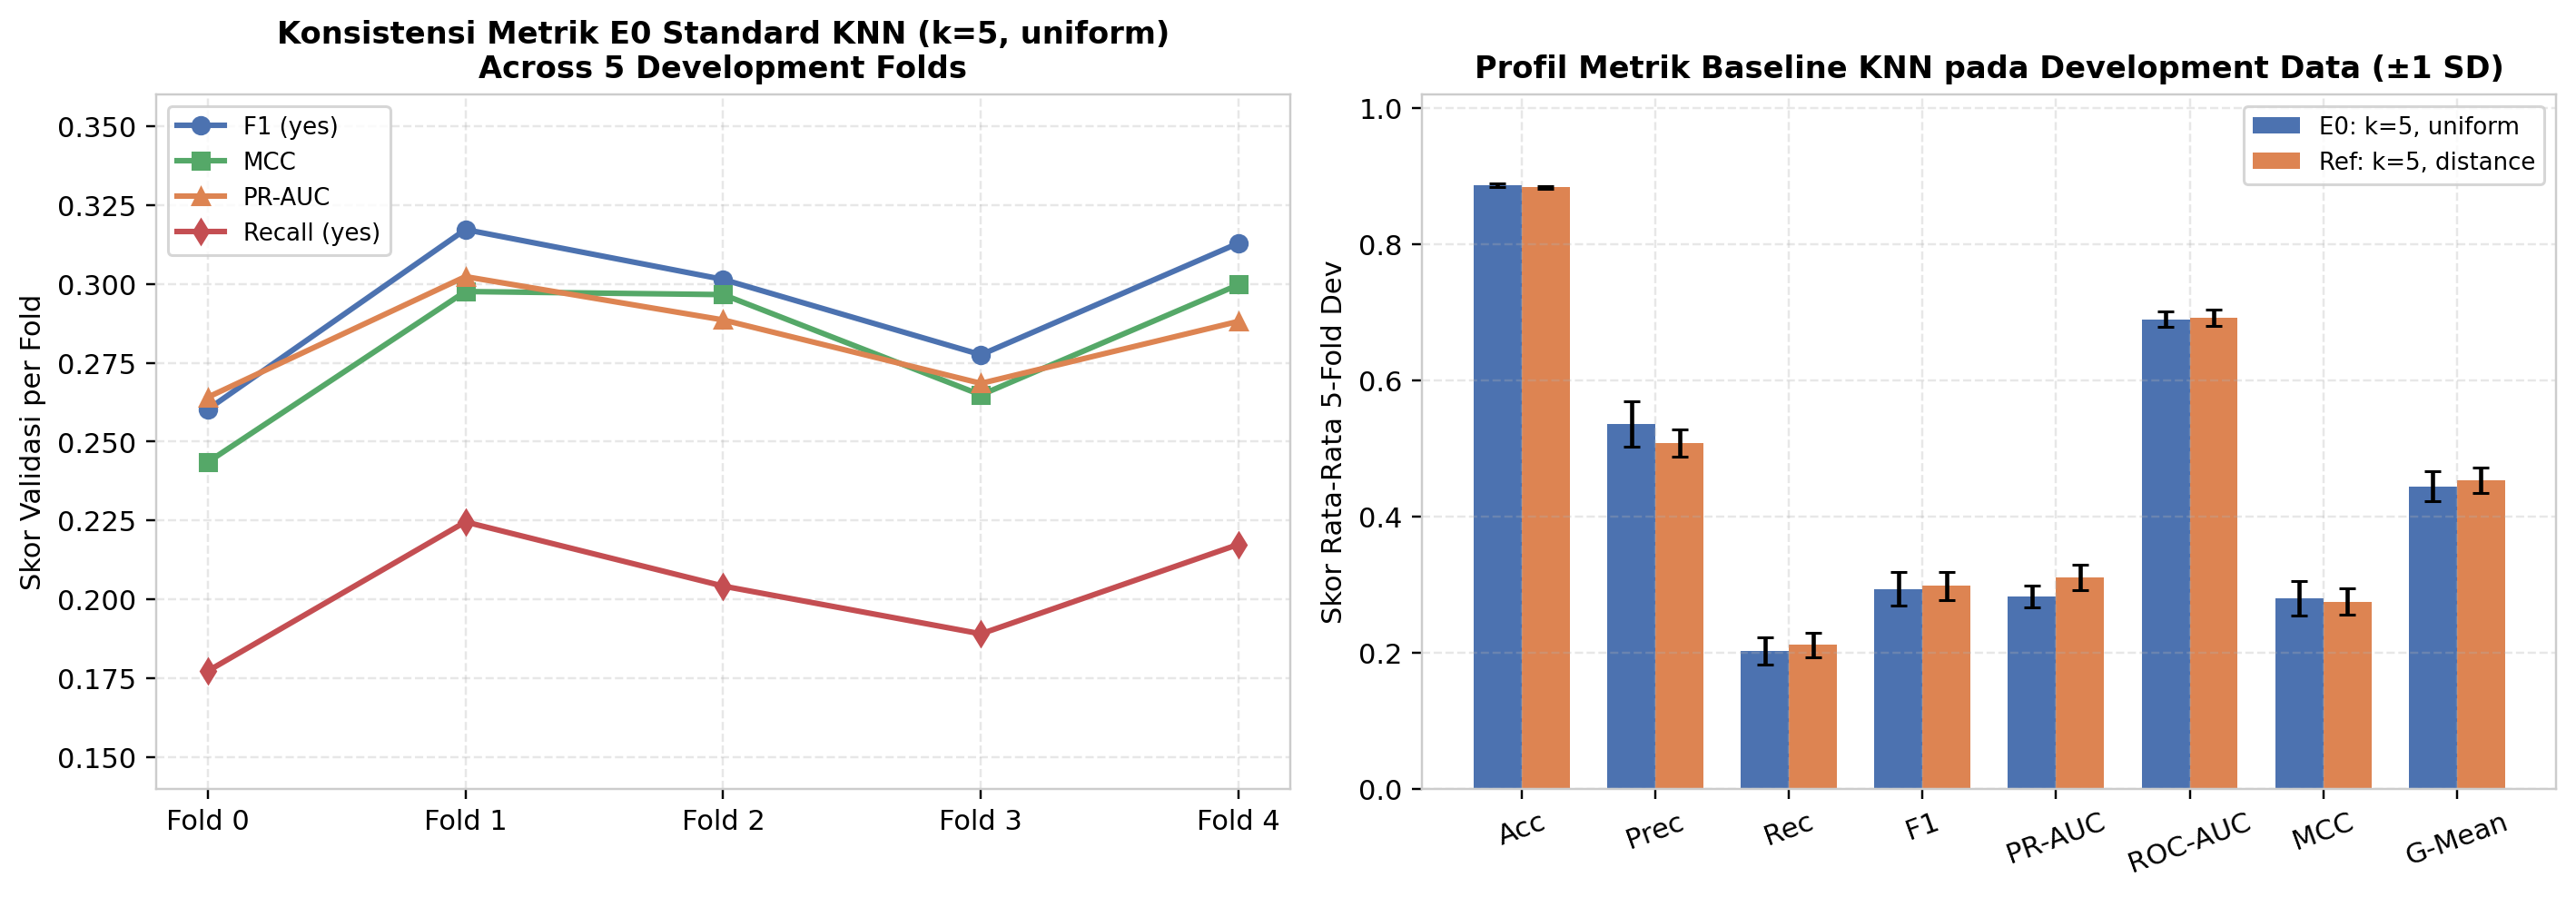

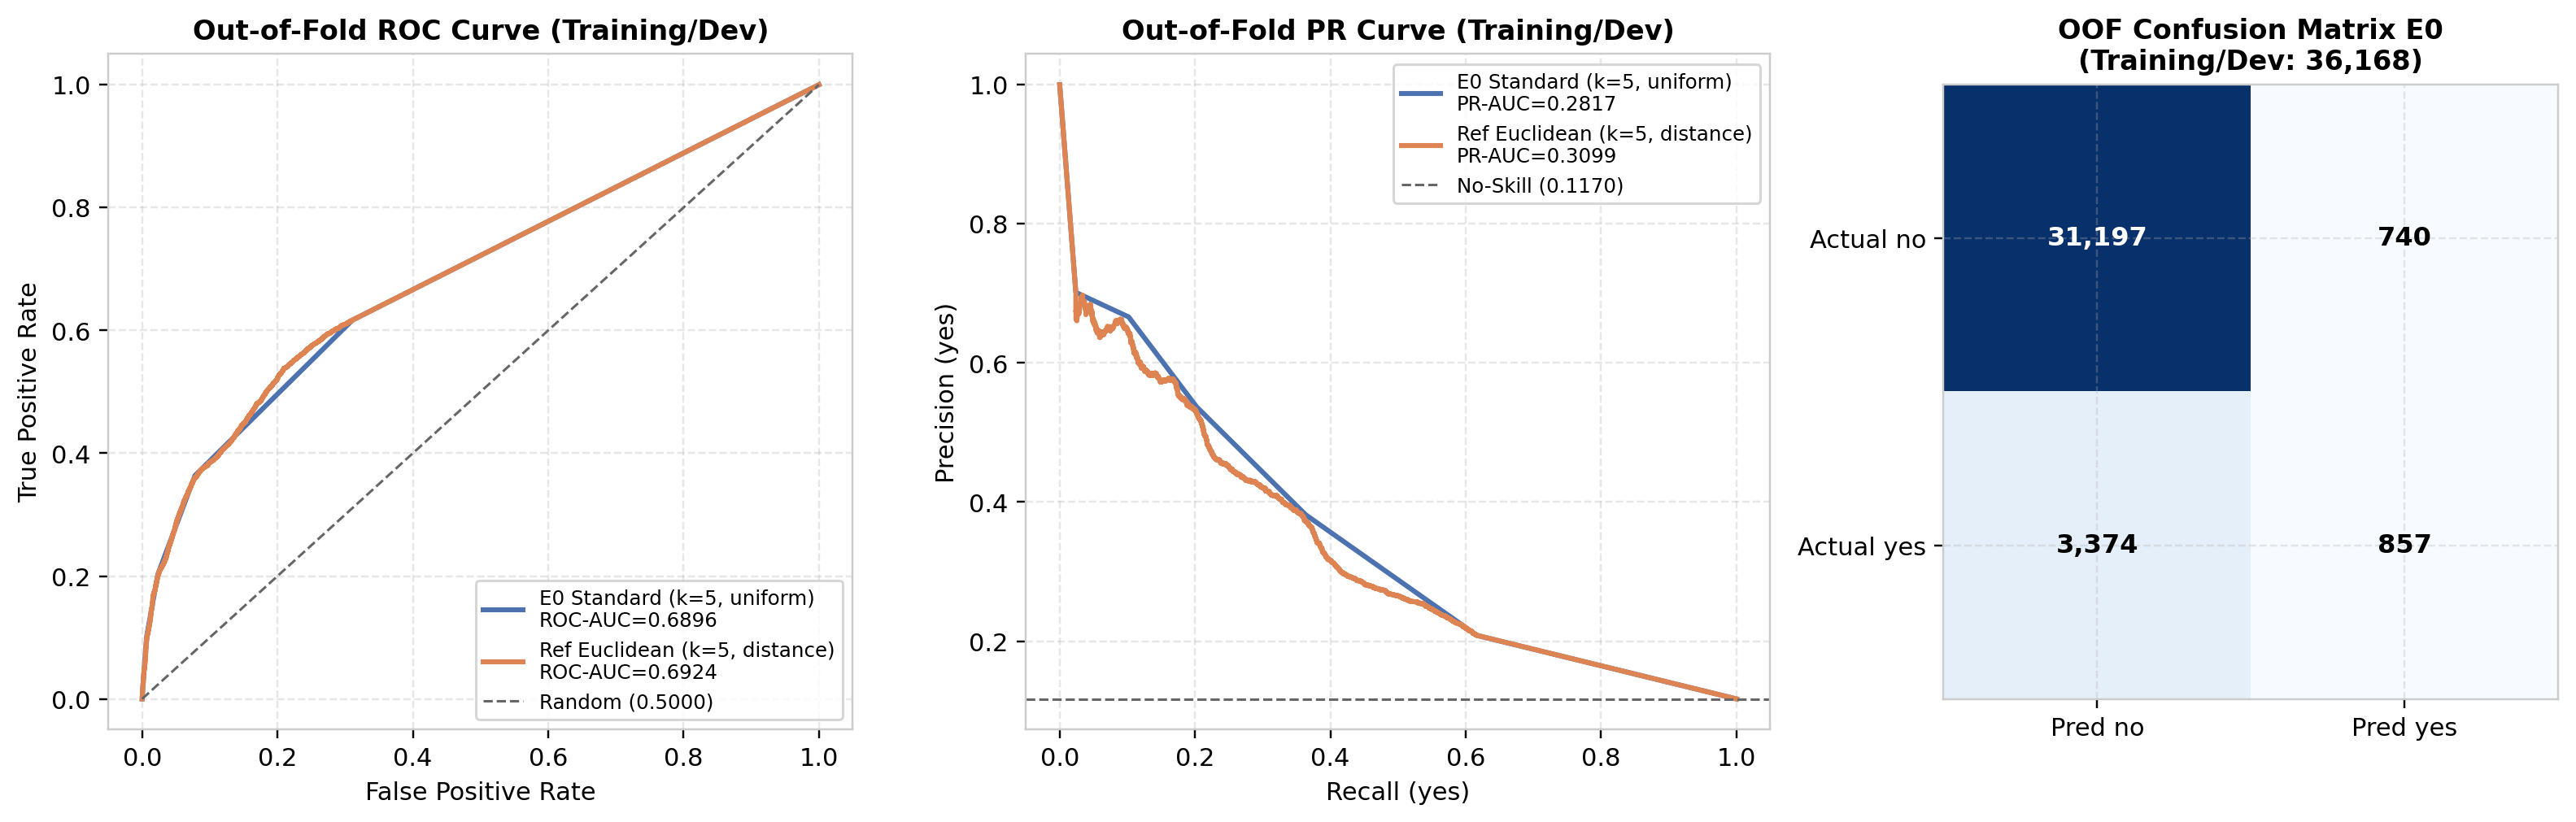

In [3]:
from IPython.display import Image
fig_dir = PROJECT_ROOT / 'outputs' / 'baseline_knn' / 'figures'
display(Image(fig_dir / '01_baseline_dev_fold_metrics.png'))
display(Image(fig_dir / '02_baseline_oof_roc_pr_confusion.png'))